In [5]:
library(ggplot2)
library(dplyr)

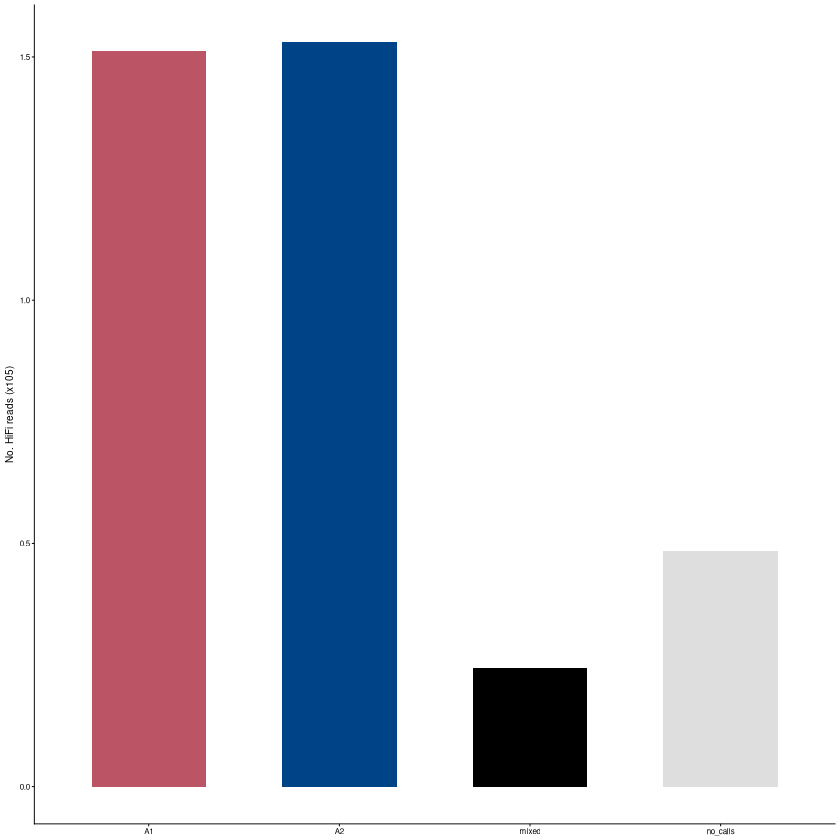

In [16]:

# Read in the data
df <- read.csv("read_counts_by_chromosome.csv")

# Sum each column
df_summed <- df %>%
  summarise(
    A1       = sum(A1),
    A2       = sum(A2),
    mixed    = sum(mixed),
    no_calls = sum(no_calls)
  ) %>%
  tidyr::pivot_longer(cols = everything(),
                      names_to  = "call_type",
                      values_to = "count")

# Set factor order
df_summed$call_type <- factor(df_summed$call_type, levels = c("A1", "A2", "mixed", "no_calls"))

# Plot
ggplot(df_summed, aes(x = call_type, y = count/100000, fill = call_type)) +
  geom_bar(stat = "identity", width = 0.6) +
  scale_fill_manual(values = c(
      "A1"       = "#BB5566",
      "mixed"    = "#000000",
      "A2"       = "#004488",
      "no_calls" = "#DEDEDE" )) +  
  scale_y_continuous(labels = scales::comma) +
  labs(
    x     = NULL,
    y     = "No. HiFi reads (x105)"
  ) +
  theme_classic(base_size = 6) + 
  theme(legend.position = "none")

ggsave("read_counts_barplot.pdf", width = 1, height = 1)